In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from google.colab import drive

drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/personality_dataset.csv'
df = pd.read_csv(file_path)
df.head(3)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,4.0,No,4.0,6.0,No,13.0,5.0,Extrovert
1,9.0,Yes,0.0,0.0,Yes,0.0,3.0,Introvert
2,9.0,Yes,1.0,2.0,Yes,5.0,2.0,Introvert


In [ ]:
dataset = df.drop(columns=['Personality'])

yes_no_columns = ['Stage_fear', 'Drained_after_socializing']
for column in yes_no_columns:
    dataset[column] = dataset[column].map({'Yes': 1, 'No': 0})

dataset = dataset.fillna(dataset.mean())

scaled_dataset = StandardScaler().fit_transform(dataset)
scaled_dataset[0:3]

array([[-0.14701445, -1.01032413,  0.01275908,  1.35061257, -0.99711228,
         1.59067969,  0.49610435],
       [ 1.30622592,  1.01533992, -1.37994399, -1.35061257,  1.02120739,
        -1.48143661, -0.19519859],
       [ 1.30622592,  1.01533992, -1.03176822, -0.45020419,  1.02120739,
        -0.29985342, -0.54085006]])

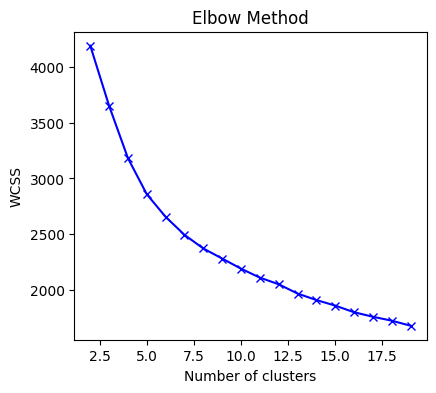

In [ ]:
# @title الف

wcss = []
kmeans_arr = []
silhouette_kms = []
K_range = range(2, 20)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=3, n_init=10)
    kmeans.fit(scaled_dataset)
    kmeans_arr.append(kmeans)
    wcss.append(kmeans.inertia_)
    silhouette_kms.append(silhouette_score(scaled_dataset, kmeans.labels_))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(K_range, wcss, 'bx-')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')

plt.show()

In [ ]:
optimal_k = 2 # Based on the fact that there's no clear "elbow" point to be found. So it must be the first point!
kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', random_state=3, n_init=10)
km_labels = kmeans_final.fit_transform(scaled_dataset)
km_labels = kmeans_final.labels_

print(f"=====> KMeans Score: {silhouette_score(scaled_dataset, km_labels):.3f}")

=====> KMeans Score: 0.674


In [ ]:
# @title ب

best_score = -1
best_params = (0, 0)
for epsilon in np.arange(0.5, 1.5, 0.1):
    for min_samples in range(2, 6):
        dbscan = DBSCAN(eps=epsilon, min_samples=min_samples)
        labels = dbscan.fit_predict(scaled_dataset)
        if len(set(labels)) > 1:
            score = silhouette_score(scaled_dataset, labels)
            if score > best_score:
                best_score = score
                best_params = (epsilon, min_samples)

dbscan_final = DBSCAN(eps=best_params[0], min_samples=best_params[1])
db_labels = dbscan_final.fit_predict(scaled_dataset)

print(f"=====> DBSCAN Optimal Params:")
print(f"=====>    epsilon = {best_params[0]}")
print(f"=====>    min_samples = {best_params[1]}")
print(f"=====> DBSCAN Score: {best_score:.3f}")

=====> DBSCAN Optimal Params:
=====>    epsilon = 1.1999999999999997
=====>    min_samples = 2
=====> DBSCAN Score: 0.674


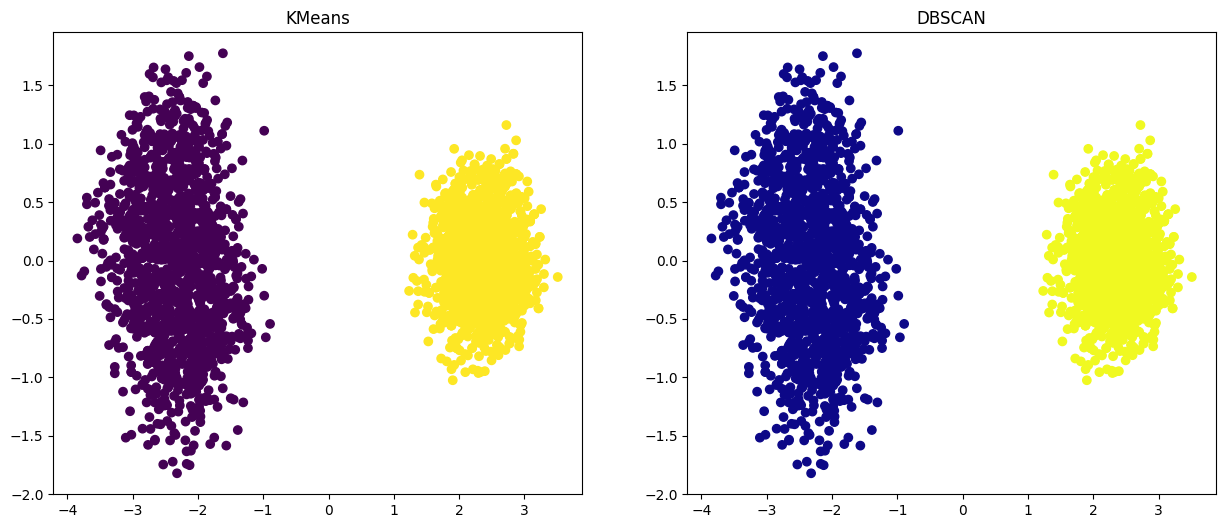

=====> Clustering Comparison:
=====> KMeans Cluster Count: 2
=====> DBSCAN Cluster Count: 2
=====> KMeans Outliers: 0
=====> DBSCAN Outliers: 0


In [ ]:
# @title ج

pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_dataset)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.scatter(pca_data[:, 0], pca_data[:, 1], c=km_labels, cmap='viridis')
ax1.set_title('KMeans')

ax2.scatter(pca_data[:, 0], pca_data[:, 1], c=db_labels, cmap='plasma')
ax2.set_title('DBSCAN')

plt.show()

km_outliers = 0
db_outliers = list(db_labels).count(-1)

print(f"=====> Clustering Comparison:")
print(f"=====> KMeans Cluster Count: {optimal_k}")
print(f"=====> DBSCAN Cluster Count: {len(set(db_labels)) - (1 if -1 in db_labels else 0)}")
print(f"=====> KMeans Outliers: {km_outliers}")
print(f"=====> DBSCAN Outliers: {db_outliers}")

همانطور که در خروجی مقایسه و نمودارهای PCA قابل مشاهده است،
هر دو الگوریتم به صورت مشابه عمل کرده‌اند و هیچ کدام داده‌ی پرتی تشخیص نداده‌اند.
همینطور هر دوی این الگوریتم‌ها،
داده‌ها را به دو خوشه تقسیم کرده‌اند و هر دو خوشه‌بندی را به یک شکل انجام داده‌اند.
ستونی که در ابتدای این برنامه از دیتاست حذف شده است،
داده‌ها را به دو خوشه‌ی درون‌گرا و برون‌گرا تقسیم می‌کرده که با توجه به نمایش داده‌ها (PCA)،
این دو خوشه نیز احتمالا مطابق با همان اطلاعات موجود در ستون درون‌گرایی یا برون‌گرایی هستند.